# Compare AT3D retrieved cloud volume extinction coefficient to CAMP2Ex insitu measured

In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

In [4]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:108: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


In [5]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')
# start_time = pd.to_datetime('2019-10-02 01:45:25')
# end_time = pd.to_datetime('2019-10-02 01:46:10')

p3_subset = p3[
    # (p3['N_L'] > 10000)
    (p3['ext_km'] > 0.3)
    & (p3.index > start_time)
    & (p3.index < end_time)
    & (p3['GPS_Altitude'] < 1250)
]

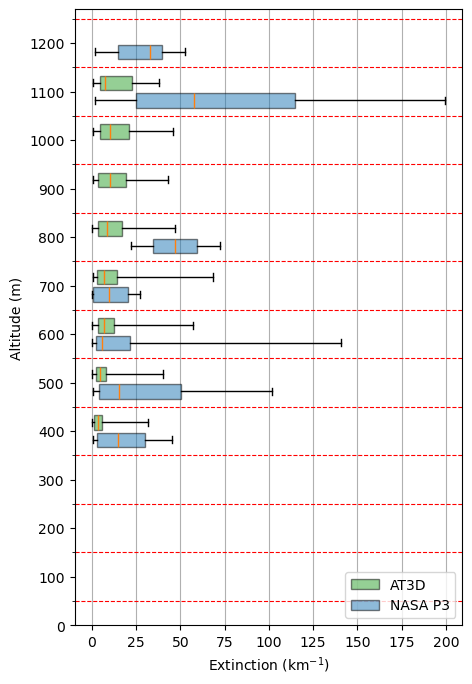

In [6]:
bins = np.arange(350, 1251, 100)

cloud = retrieval.threshold_cloud(r.solvers_retrieval[0.67].medium['cloud'], extinction_th=[0.3, np.inf], tau_th=[0.3, np.inf])
at3d_ext_box = []
for i in range(len(bins)-1):
    tmp_cloud = cloud.sel(z=slice(1e-3*bins[i], 1e-3*bins[i+1]))
    ext = tmp_cloud.extinction.data
    at3d_ext_box.append(ext[tmp_cloud.cloud_volume_mask.data==1])

p3_ext_box = []
for i in range(len(bins)-1):
    tmp = p3_subset.loc[
        (p3_subset['GPS_Altitude'] >= bins[i])
        & (p3_subset['GPS_Altitude'] < bins[i+1])
    ]['ext_km'].to_numpy()
    p3_ext_box.append(tmp)

box_kwargs = {
    'vert':False,
    'manage_ticks':False,
    'patch_artist':True,
    'widths':30,
    'whis':(0,100)
}

f, ax = plt.subplots(1, 1, figsize=(5, 8))
at3d_bplot = ax.boxplot(at3d_ext_box, positions=bins[:-1]+68, **box_kwargs)
for patch in at3d_bplot['boxes']:
    patch.set_facecolor('tab:green')
    patch.set_alpha(0.5)

p3_bplot = ax.boxplot(p3_ext_box, positions=bins[:-1]+32, **box_kwargs)
for patch in p3_bplot['boxes']:
    patch.set_facecolor('tab:blue')
    patch.set_alpha(0.5)

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
ax.grid(visible=True, which='major', axis='x')
ax.grid(visible=True, which='minor', axis='y', color='r', linestyle='--')

ax.set_yticks(np.arange(0, 1400, 100))
ax.set_yticks(np.arange(50, 1300, 100), minor=True)
ax.set_ylim([0, 1270])
ax.set_xlabel(r'Extinction (km$^{-1}$)')

ax.legend([at3d_bplot['boxes'][0], p3_bplot['boxes'][0]], ['AT3D', 'NASA P3'], loc='lower right')

In [7]:
from scipy.stats import ks_2samp
# i = 5
# d_stat, p_value = ks_2samp(p3_ext_box[i], at3d_ext_box[i])

print('{:<10} | {:<14} | {:<14}'.format('Alt', 'D-stat', 'p-value'))
for i in range(len(p3_ext_box)):
    if((len(p3_ext_box[i]) > 0) & (len(at3d_ext_box[i]) > 0)):
        d_stat, p_value = ks_2samp(p3_ext_box[i], at3d_ext_box[i])
        print('{:<10} | {:<14.8f} | {:<14.8f}'.format(i, d_stat, p_value))

Alt        | D-stat         | p-value       
0          | 0.48233216     | 0.22458432    
1          | 0.46389773     | 0.00000000    
2          | 0.20376845     | 0.00021407    
3          | 0.43415638     | 0.34329681    
4          | 0.85789474     | 0.04428447    
7          | 0.64008621     | 0.00016039    


In [8]:
from scipy.stats import ttest_ind

print('{:<10} | {:<14} | {:<14}'.format('Alt', 't-stat', 'p-value', 'df'))
for i in range(len(p3_ext_box)):
    if((len(p3_ext_box[i]) > 0) & (len(at3d_ext_box[i]) > 0)):
        result = ttest_ind(p3_ext_box[i], at3d_ext_box[i])
        t_stat = result.statistic
        p_value = result.pvalue
        print('{:<10} | {:<14.8f} | {:<14.8f}'.format(i, t_stat, p_value))

Alt        | t-stat         | p-value       
0          | 5.38058934     | 0.00000016    
1          | 13.82718653    | 0.00000000    
2          | 6.21586298     | 0.00000000    
3          | 0.53753151     | 0.59138841    
4          | 5.15375559     | 0.00000064    
7          | 3.96791077     | 0.00027045    
